# Introduction to GradCam Exercises

# =========================
# Cell 1: Imports & Setup
# =========================

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
import random

print("TensorFlow:", tf.__version__)
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

TensorFlow: 2.19.0


## ==========================================
## Cell 2: Load Dataset (Option A: CIFAR-10)
## ==========================================

In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

class_names = ['airplabe', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

val_size = 5000
x_val = x_train[-val_size:]
y_val = y_train[-val_size:]
x_train2 = x_train[:-val_size]
y_train2 = y_train[:-val_size]

print("Train:", x_train2.shape, y_train2.shape)
print("Val:", x_val.shape, y_val.shape)
print("Test:", x_test.shape, y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 20s 0us/step
Train: (45000, 32, 32, 3) (45000, 1)
Val: (5000, 32, 32, 3) (5000, 1)
Test: (10000, 32, 32, 3) (10000, 1)


# =========================
# Cell 3: Visualize Samples
# =========================

/tmp/ipython-input-1040673301.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(class_names[int(labels[idx])], fontsize=9)


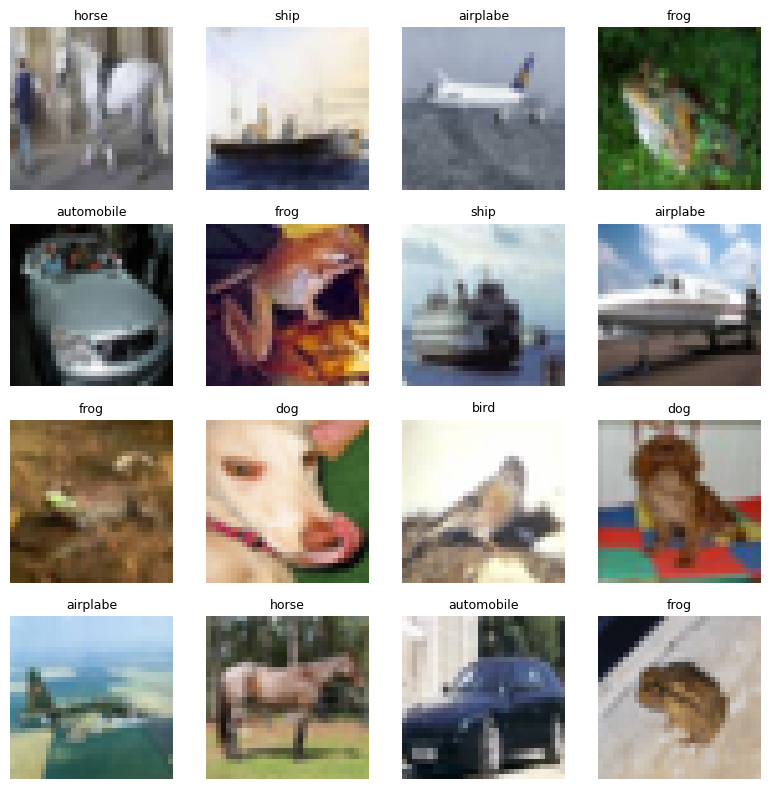

In [3]:
def show_grid(images, labels, class_names, n=16):
  plt.figure(figsize=(8, 8))
  idxs = np.random.choice(len(images), n, replace=False)
  for i, idx in enumerate(idxs):
    plt.subplot(4, 4, i + 1)
    plt.imshow(images[idx])
    plt.title(class_names[int(labels[idx])], fontsize=9)
    plt.axis("off")
  plt.tight_layout()
  plt.show()

show_grid(x_train, y_train, class_names, n=16)

# =========================
# Cell 4: Build CNN Model
# =========================

In [4]:
def build_cnn(input_shape=(32, 32, 3), num_classes=10):
  inputs = keras.Input(shape=input_shape)

  x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
  x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)
  x = layers.MaxPool2D(2)(x)
  x = layers.Dropout(0.25)(x)

  x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
  x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
  x = layers.MaxPool2D(2)(x)
  x = layers.Dropout(0.25)(x)

  x = layers.Conv2D(128, 3, padding="same", activation="relu", name="last_conv")(x)
  x = layers.MaxPool2D()(x)

  x = layers.GlobalAveragePooling2D()(x)
  x = layers.Dropout(0.3)(x)
  outputs = layers.Dense(num_classes, activation="softmax")(x)

  return keras.Model(inputs, outputs)

model = build_cnn(input_shape=x_train2.shape[1:], num_classes=len(class_names))
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ last_conv (Conv2D)              │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 140,714 (549.66 KB)

 Trainable params: 140,714 (549.66 KB)

 Non-trainable params: 0 (0.00 B)

# =========================
# Cell 5: Compile & Train
# =========================

In [5]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5, min_lr=1e-5),
]

history = model.fit(
    x_train2, y_train2,
    validation_data=(x_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 18s 14ms/step - accuracy: 0.2499 - loss: 1.9385 - val_accuracy: 0.4568 - val_loss: 1.4503 - learning_rate: 0.0010
Epoch 2/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.4616 - loss: 1.4581 - val_accuracy: 0.5690 - val_loss: 1.2046 - learning_rate: 0.0010
Epoch 3/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5405 - loss: 1.2548 - val_accuracy: 0.6324 - val_loss: 1.0496 - learning_rate: 0.0010
Epoch 4/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.5904 - loss: 1.1366 - val_accuracy: 0.6498 - val_loss: 1.0002 - learning_rate: 0.0010
Epoch 5/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6201 - loss: 1.0600 - val_accuracy: 0.6786 - val_loss: 0.9179 - learning_rate: 0.0010
Epoch 6/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.6427 - loss: 1.0018 - val_accuracy: 0.6940 - val_loss: 0.8761 - learning_rate: 0.0010
Epoch 7/20
704/704 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.6558 - loss: 0.9585 

# =========================
# Cell 6: Plot Curves
# =========================

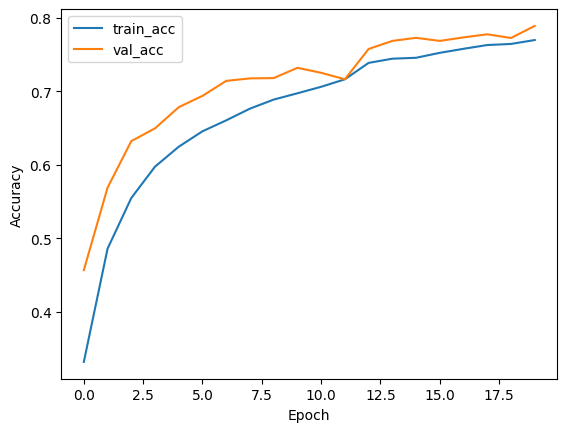

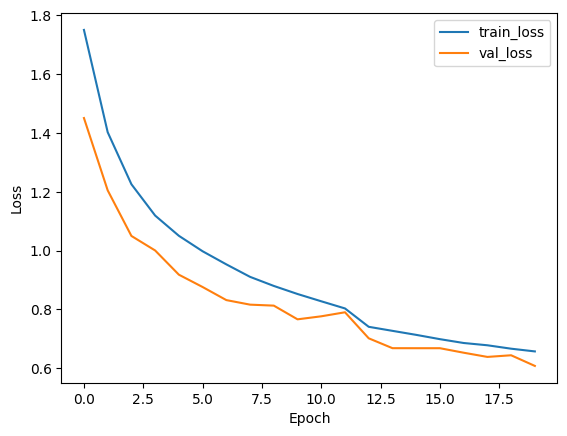

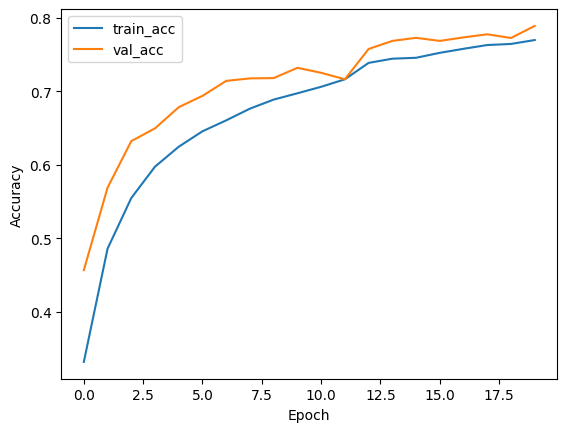

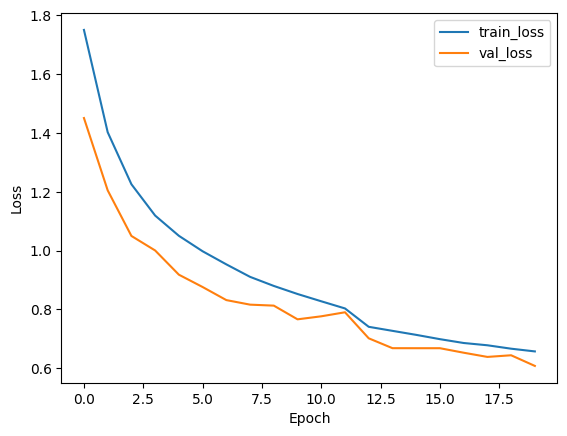

In [6]:
def plot_history(hist):
  plt.figure()
  plt.plot(hist.history["accuracy"], label="train_acc")
  plt.plot(hist.history["val_accuracy"], label="val_acc")
  plt.xlabel("Epoch")
  plt.ylabel("Accuracy")
  plt.legend()
  plt.show()

  plt.figure()
  plt.plot(hist.history["loss"], label="train_loss")
  plt.plot(hist.history["val_loss"], label="val_loss")
  plt.xlabel("Epoch")
  plt.ylabel("Loss")
  plt.legend()
  plt.show()

plot_history(history)
plot_history(history)

# =========================
# Cell 7: Evaluate & Confusion Matrix
# =========================

Test accuracy: 0.7789
              precision    recall  f1-score   support

    airplabe       0.79      0.80      0.79      1000
  automobile       0.92      0.87      0.90      1000
        bird       0.75      0.64      0.69      1000
         cat       0.69      0.45      0.55      1000
        deer       0.73      0.78      0.75      1000
         dog       0.60      0.80      0.69      1000
        frog       0.82      0.82      0.82      1000
       horse       0.76      0.85      0.81      1000
        ship       0.89      0.88      0.89      1000
       truck       0.86      0.89      0.88      1000

    accuracy                           0.78     10000
   macro avg       0.78      0.78      0.78     10000
weighted avg       0.78      0.78      0.78     10000



<Figure size 1000x1000 with 0 Axes>

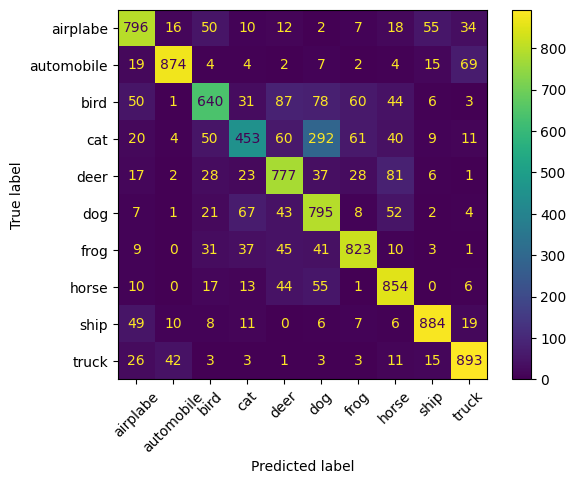

In [14]:
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test accuracy:", round(float(test_acc), 4))

y_prob = model.predict(x_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = y_test.squeeze()

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
plt.figure(figsize=(10, 10))
disp.plot(xticks_rotation=45)
plt.show()

# =========================
# Cell 8: Grad-CAM Implementation
# =========================

In [17]:
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
  grad_model = tf.keras.models.Model(
      [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output])

  with tf.GradientTape() as tape:
    conv_outputs, predictions = grad_model(img_array)
    if pred_index is None:
      pred_index = tf.argmax(predictions[0])
    class_channel = predictions[:, pred_index]

  grads = tape.gradient(class_channel, conv_outputs)

  pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

  conv_outputs = conv_outputs[0]
  heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
  heatmap = tf.squeeze(heatmap)

  heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
  return heatmap.numpy()

def show_gradcam(img, heatmap, alpha=0.4):
  heatmap_resized = tf.image.resize(heatmap[..., np.newaxis], (img.shape[0], img.shape[1])).numpy().squeeze()

  plt.figure(figsize=(8, 4))
  plt.subplot(1, 2, 1)
  plt.imshow(img)
  plt.axis("off")
  plt.title("Original")

  plt.subplot(1, 2, 2)
  plt.imshow(img)
  plt.imshow(heatmap_resized, alpha=alpha, cmap="jet")
  plt.title("Grad-CAM Overlay")
  plt.tight_layout()
  plt.show()

# ===========================================
# Cell 9: Grad-CAM on Correct vs Incorrect
# ===========================================


Grad-CAM: Correct Predictions (5 examples)
Index 6302 | True: airplabe | Pred: airplabe | Conf: 0.906


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor']]
Received: inputs=Tensor(shape=(1, 32, 32, 3))
  warnings.warn(msg)


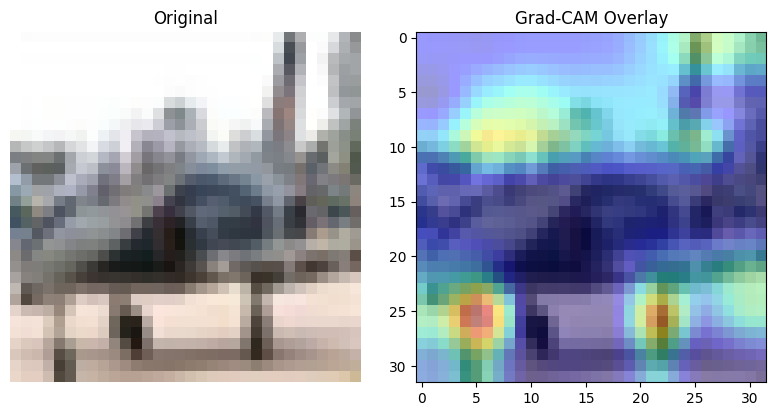

Index 5968 | True: airplabe | Pred: airplabe | Conf: 0.817


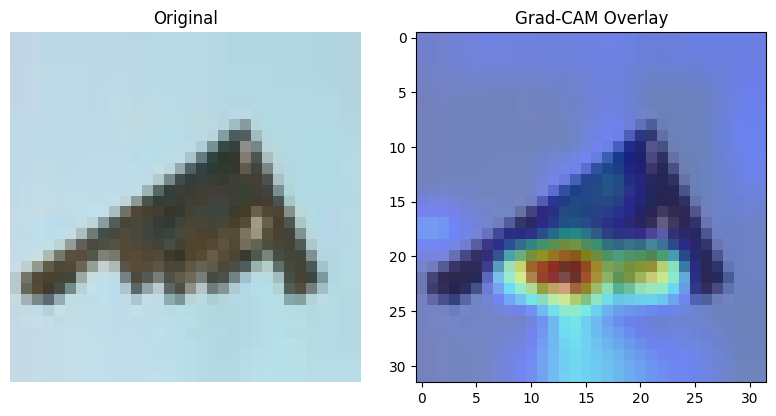

Index 7450 | True: automobile | Pred: automobile | Conf: 0.994


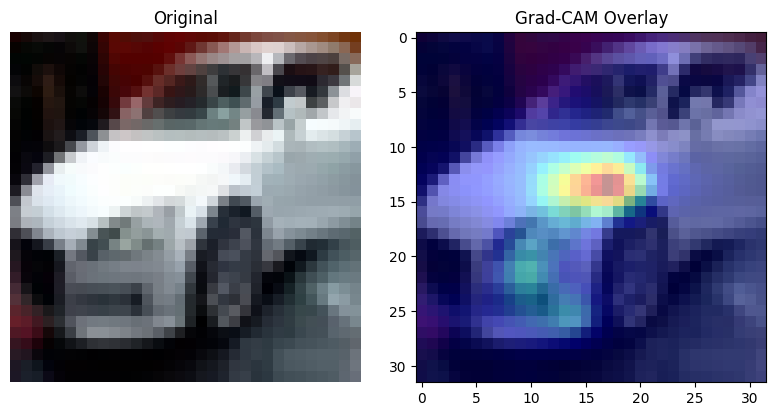

Index 7291 | True: cat | Pred: cat | Conf: 0.931


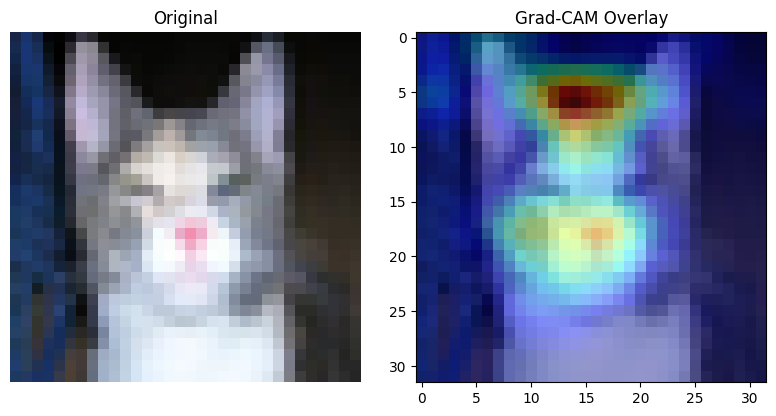

Index 8609 | True: frog | Pred: frog | Conf: 0.818


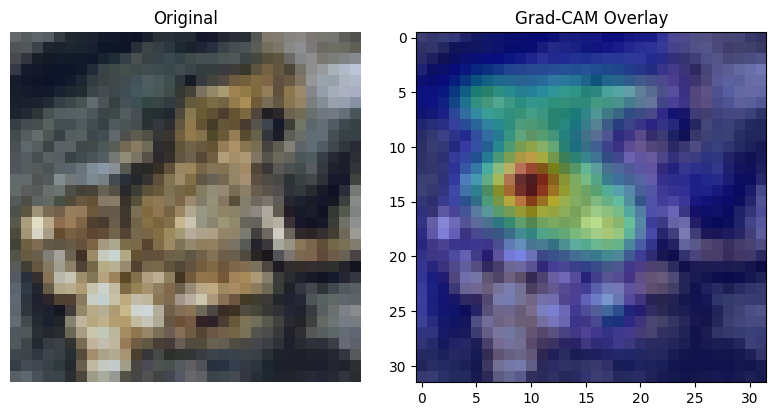


Grad-CAM: Incorrect Predictions (5 examples)
Index 9223 | True: automobile | Pred: truck | Conf: 0.718


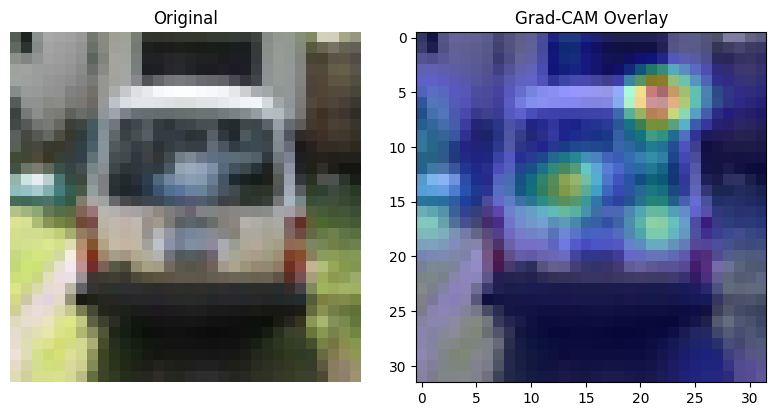

Index 3785 | True: frog | Pred: dog | Conf: 0.459


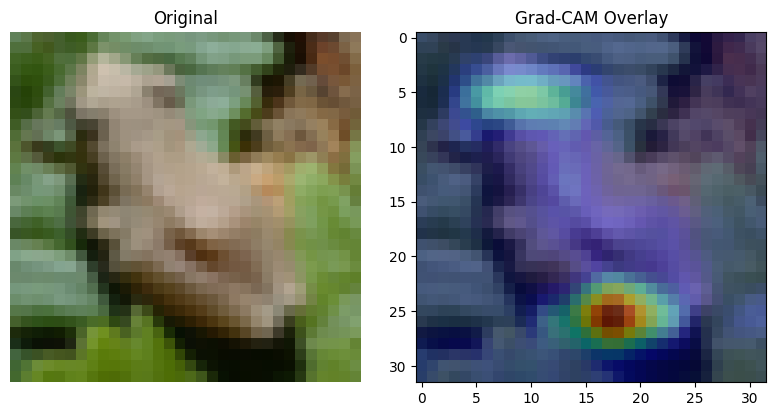

Index 5739 | True: bird | Pred: frog | Conf: 0.699


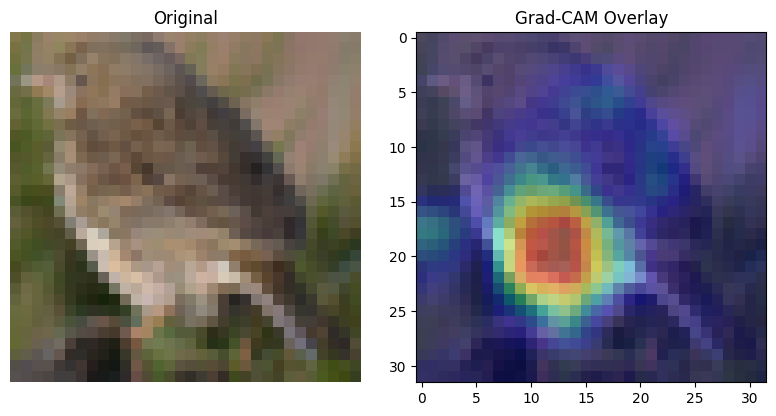

Index 6213 | True: cat | Pred: frog | Conf: 0.809


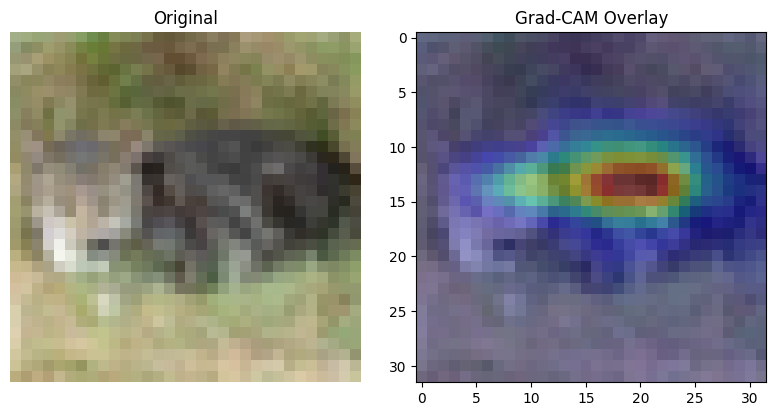

Index 725 | True: bird | Pred: airplabe | Conf: 0.392


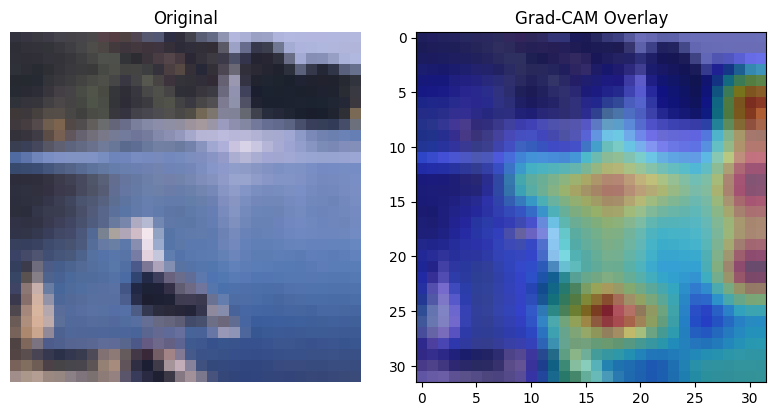

In [18]:
correct_idx = np.where(y_pred == y_true)[0]
wrong_idx = np.where(y_pred != y_true)[0]

correct_pick = np.random.choice(correct_idx, 5, replace=False)
wrong_pick = np.random.choice(wrong_idx, 5, replace=False)

def run_gradcam_examples(idxs, title):
  print("\n" + "="*60)
  print(title)
  print("="*60)
  for idx in idxs:
    img = x_test[idx]
    true_label = class_names[y_true[idx]]
    pred_label = class_names[y_pred[idx]]
    conf = float(np.max(y_prob[idx]))

    img_array = np.expand_dims(img, axis=0)
    heatmap = make_gradcam_heatmap(img_array, model, "last_conv", pred_index=None)

    print(f"Index {idx} | True: {true_label} | Pred: {pred_label} | Conf: {conf:.3f}")
    show_gradcam(img, heatmap)

run_gradcam_examples(correct_pick, "Grad-CAM: Correct Predictions (5 examples)")
run_gradcam_examples(wrong_pick, "Grad-CAM: Incorrect Predictions (5 examples)")